# §2 Data profiling and quality audit (Stages S2–S3)

This section works out where the data can be trusted and where they cannot, and turns each finding into a recorded decision. It starts by re-checking the provenance and specification work of Stage S2 (hashes, codebook-derived specification, minimisation). The Stage S3 audit follows in nine numbered items:

1. XPT read artefact and zero-weight semantics
2. Completeness, uniqueness and the sample funnel
3. Per-variable sentinel map
4. Cost of a blanket recode
5. Consistency checks
6. Top-coding
7. Missing-data mechanism for HbA1c
8. Outliers: a three-layer rule
9. Data-quality dimension matrix

Each item follows the same pattern: *why* the check is needed, the code that computes it, and *so what*, giving the computed numbers and the decision they support. Numbers that the process document fixes (§8) are asserted with a tolerance. Every number is stored in `results/metrics_S2.json` / `results/metrics_S3.json`, tables in `results/S3/`, and the decisions in `governance/register/S2.csv` and `S3.csv`.

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
from IPython.display import display

from src import nhanes_io as io

pd.set_option("display.width", 160, "display.max_colwidth", 70, "display.max_rows", 80)
OI = C.OKABE_ITO
OUT = C.RESULTS_DIR / "S3"
OUT.mkdir(parents=True, exist_ok=True)
(C.RESULTS_DIR / "S2").mkdir(parents=True, exist_ok=True)
TODAY = "2026-10-11"
REGISTER_COLS = ["dr_id", "stage", "date", "type", "finding", "evidence_ref", "evidence_value", "decision",
                 "alternatives_rejected", "hyp_id", "status", "check_verdict", "check_note", "loop_ref",
                 "change_request", "commit"]
M2, M3 = {}, {}   # metrics stored for S2 and S3


def close(a, b, tol=0.0):
    """Assert helper: |a - b| <= tol."""
    return abs(float(a) - float(b)) <= tol


def write_register(stage, rows):
    reg = pd.DataFrame(rows)
    for c in REGISTER_COLS:
        if c not in reg:
            reg[c] = ""
    reg = reg[REGISTER_COLS]
    reg.to_csv(C.GOVERNANCE_DIR / "register" / f"{stage}.csv", index=False, lineterminator="\n")
    return reg

## 0 Provenance, specification and minimisation (Stage S2 checks)

**Why.** An audit is only as good as its inputs. Three things are checked before any profiling:

- the raw files are the unmodified CDC files (SHA-256 against `MANIFEST.sha256`);
- the variable specification `config/variable_spec.csv` agrees with the CDC codebooks and with the columns actually present in the XPT files, because every sentinel code must have a traceable source;
- the loader keeps only what the purpose needs (data minimisation, GDPR Art. 5(1)(c)).

In [2]:
integrity = io.ensure_raw_data(download=False)
print(f"raw files verified against MANIFEST.sha256: {len(integrity['verified'])}/{integrity['n_files']}; mismatched: {integrity['mismatched']}")
assert integrity["mismatched"] == [] and len(integrity["verified"]) == 16

spec = io.load_spec()
problems = io.verify_spec(spec)
print("verify_spec problems:", problems or "none")
assert problems == []

inc = io.included(spec)
role_tab = (inc[inc["var"] != "SEQN"].groupby(["role", "admissible"]).size().unstack(fill_value=0))
display(role_tab)
tier_tab = spec[spec["var"] != "SEQN"].groupby("use_tier").size().rename("variables").to_frame()
display(tier_tab)

min_files, min_cols = io.minimisation_report(spec)
min_files.to_csv(C.RESULTS_DIR / "S2" / "minimisation_report.csv", index=False, lineterminator="\n")
min_cols.to_csv(C.RESULTS_DIR / "S2" / "minimisation_columns.csv", index=False, lineterminator="\n")
display(min_files[["file", "use_tier", "rows", "cols_raw", "cols_kept", "cols_dropped"]])
n_raw, n_kept, n_drop = (int(min_files[c].sum()) for c in ("cols_raw", "cols_kept", "cols_dropped"))
print(f"columns: raw {n_raw}, kept {n_kept}, dropped {n_drop}; every dropped column has a reason:",
      bool(min_cols.loc[min_cols["decision"] == "drop", "reason"].str.len().gt(0).all()))
assert n_raw == len(spec) == 175 and n_kept + n_drop == n_raw
assert min_cols.loc[min_cols["decision"] == "drop", "reason"].str.len().gt(0).all()

n_sentinel_vars = len(io.sentinel_map(spec))
cont_inc = inc[(inc["dtype"] == "continuous") & inc["file"].isin(["BMX_L", "BPXO_L", "GHB_L", "TCHOL_L", "HDL_L", "GLU_L", "TRIGLY_L"])]
print(f"included variables with codebook refusal/don't-know codes: {n_sentinel_vars}; "
      f"continuous lab/exam measures with such codes: {int((cont_inc['sentinel_codes'] != '').sum())} of {len(cont_inc)}")
assert (cont_inc["sentinel_codes"] == "").all() and len(cont_inc) == 21 and n_sentinel_vars == 25

raw files verified against MANIFEST.sha256: 16/16; mismatched: []


verify_spec problems: none


admissible,N,T1,T2
role,,,
audit,3,0,0
cohort_filter,2,0,0
design,2,0,0
feature,0,30,2
label,2,0,0
leak,8,0,0
optional,5,0,0
redundancy,2,0,0
side,2,0,0


,variables
use_tier,
core,41
excluded,97
optional,5
recommended,10
redundancy_demo,2
side_analysis,4


,file,use_tier,rows,cols_raw,cols_kept,cols_dropped
0,DEMO_L,core,11933,27,13,14
1,GHB_L,core,7199,3,3,0
2,GLU_L,side_analysis,3996,4,3,1
3,BMX_L,core,8860,22,7,15
4,BPXO_L,core,7801,12,10,2
5,TCHOL_L,core,8068,4,2,2
6,HDL_L,core,8068,4,2,2
7,TRIGLY_L,side_analysis,3996,10,3,7
8,DIQ_L,core,11744,9,9,0
9,BPQ_L,recommended,8501,6,3,3


columns: raw 175, kept 78, dropped 97; every dropped column has a reason: True
included variables with codebook refusal/don't-know codes: 25; continuous lab/exam measures with such codes: 0 of 21


**So what.** All 16 raw files match their recorded hashes, so every number below comes from the CDC release dated 2026-10-10. The specification has one row for each of the 175 raw columns, and `verify_spec` finds no disagreement with the codebooks or the XPT headers. The loader keeps 78 columns and drops 97. Each dropped column has a stated reason: child-only items, country of birth and years in the US (quasi-identifiers), military service, household reference-person fields, SI-unit duplicates, unrelated MCQ items and duplicate weight columns.

25 included variables carry codebook refusal or don't-know codes, and all of them are questionnaire items. None of the 21 continuous laboratory and examination measures has such a code. The per-variable sentinel map therefore leaves every measurement untouched; item 4 shows why this matters.

In [3]:
M2.update({
    "raw_files_verified": len(integrity["verified"]), "hash_mismatches": len(integrity["mismatched"]),
    "spec_rows": len(spec), "spec_problems": len(problems),
    "minimisation": {"cols_raw": n_raw, "cols_kept": n_kept, "cols_dropped": n_drop,
                     "per_file": min_files.set_index("file")[["cols_raw", "cols_kept", "cols_dropped"]].to_dict("index")},
    "use_tier_counts": tier_tab["variables"].to_dict(),
    "role_admissible": {f"{r}|{a}": int(v) for (r, a), v in role_tab.stack().items() if v},
    "n_sentinel_variables": n_sentinel_vars,
})

## 1 XPT read artefact and zero-weight semantics

**Why.** When pandas reads a SAS transport (XPT) file, a stored zero comes back as 5.397605e-79 (= 16⁻⁶⁵). This is a floating-point artefact of the reader, not a SAS missing-value code. Left in place it creates a spurious minimum and breaks `== 0` tests such as "zero weight" or "no activity". The repair has to keep NaN as NaN. `x.where(|x| >= 1e-10, 0)` is the tempting one-liner, but it also turns every NaN into 0, because NaN fails the comparison.

In [4]:
art = io.xpt_artefact_audit()
art_file = art.groupby("file")["n_artefact"].sum().reindex(C.NHANES_FILES)
art_vars = art[art["n_artefact"] > 0].sort_values(["file", "n_artefact"], ascending=[True, False])
display(art_vars.reset_index(drop=True))
n_art = int(art_file.sum())
files_hit = art_file[art_file > 0].index.tolist()
print(f"artefact cells: {n_art:,} in {len(files_hit)} files {files_hit}; clean files: {art_file[art_file == 0].index.tolist()}")
art.to_csv(OUT / "xpt_artefacts.csv", index=False, lineterminator="\n")

# demonstrate the NaN-preservation requirement on one affected file
paq = io.read_xpt("PAQ_L")
fixed, n_fixed = io.fix_xpt(paq)
num = paq.select_dtypes("number")
wrong = num.where(num.abs() >= C.XPT_ZERO_EPS, 0.0)   # the tempting `where` version: NaN fails the test -> 0
nan_before, nan_after, nan_wrong = int(num.isna().sum().sum()), int(fixed[num.columns].isna().sum().sum()), int(wrong.isna().sum().sum())
residual = int(io._artefact_mask(fixed).to_numpy().sum())
print(f"PAQ_L: fixed {n_fixed:,} cells; NaN before {nan_before:,}, after mask-fix {nan_after:,}, after where-fix {nan_wrong:,}; residual 0<|x|<1e-10: {residual}")
assert nan_after == nan_before and residual == 0 and nan_wrong < nan_before

# whole-project check: all files repaired, NaN count unchanged
tot_fixed = 0
for f in C.NHANES_FILES:
    raw = io.read_xpt(f)
    fx, k = io.fix_xpt(raw)
    tot_fixed += k
    assert io._artefact_mask(fx).to_numpy().sum() == 0
    assert fx.select_dtypes("number").isna().sum().sum() == raw.select_dtypes("number").isna().sum().sum()
assert n_art == tot_fixed == 13676 and len(files_hit) == 9

,file,var,n_artefact
0,DEMO_L,WTMEC2YR,3073
1,DEMO_L,RIDAGEYR,189
2,DEMO_L,INDFMPIR,100
3,DEMO_L,RIDAGEMN,17
4,DEMO_L,RIDEXAGM,4
5,GHB_L,WTPH2YR,449
6,GLU_L,WTSAF2YR,635
7,HDL_L,WTPH2YR,752
8,INQ_L,INDFMMPI,218
9,PAQ_L,PAD810Q,4413


artefact cells: 13,676 in 9 files ['DEMO_L', 'GHB_L', 'GLU_L', 'TCHOL_L', 'HDL_L', 'TRIGLY_L', 'INQ_L', 'SMQ_L', 'PAQ_L']; clean files: ['BMX_L', 'BPXO_L', 'DIQ_L', 'BPQ_L', 'MCQ_L', 'HIQ_L', 'HUQ_L']
PAQ_L: fixed 6,117 cells; NaN before 6,276, after mask-fix 6,276, after where-fix 0; residual 0<|x|<1e-10: 0


Several of the repaired zeros have a meaning defined in the codebook. A zero weight marks a participant outside that weight's sub-sample, so it must become missing before any weighted calculation:

In [5]:
demo = io.load_file("DEMO_L", minimise=False)[0]
ghb = io.load_file("GHB_L", minimise=False)[0]
glu = io.load_file("GLU_L", minimise=False)[0]
zw = pd.DataFrame([
    ["WTMEC2YR = 0", int((demo["WTMEC2YR"] == 0).sum()), "not MEC-examined", int((demo["RIDSTATR"] == 1).sum())],
    ["WTPH2YR = 0 (GHB_L)", int((ghb["WTPH2YR"] == 0).sum()), "no blood sample provided", None],
    ["WTSAF2YR = 0 (GLU_L)", int((glu["WTSAF2YR"] == 0).sum()), "fasting sub-sample non-response", None],
], columns=["condition", "n", "codebook meaning", "cross-check: RIDSTATR = 1 (interview only)"])
display(zw)
coh = io.build_cohort()
zero_in_cohort = int((coh["WTPH2YR"] == 0).sum())
print(f"cohort rows with WTPH2YR = 0: {zero_in_cohort}; WTPH2YR missing: {int(coh['WTPH2YR'].isna().sum())}")
assert zw.loc[0, "n"] == 3073 == zw.loc[0, "cross-check: RIDSTATR = 1 (interview only)"]
assert zw.loc[1, "n"] == 449 and zero_in_cohort == 0

,condition,n,codebook meaning,cross-check: RIDSTATR = 1 (interview only)
0,WTMEC2YR = 0,3073,not MEC-examined,3073.0
1,WTPH2YR = 0 (GHB_L),449,no blood sample provided,NaN
2,WTSAF2YR = 0 (GLU_L),635,fasting sub-sample non-response,NaN


cohort rows with WTPH2YR = 0: 0; WTPH2YR missing: 0


**So what.** The artefact affects 13,676 cells in 9 of the 16 files: DEMO, GHB, GLU, TCHOL, HDL, TRIGLY, INQ, SMQ and PAQ. BMX, BPXO, DIQ, BPQ, MCQ, HIQ and HUQ are clean. Most of the affected cells are weights or frequencies whose true value is 0. Examples are the 3,073 zero exam weights and the 4,413 people with zero vigorous-activity sessions (`PAD810Q`).

On `PAQ_L` the `mask` repair keeps the NaN count unchanged. The `where` version would silently turn the missing cells into zeros, which reads as "no physical activity" for people who never answered. After the repair no value with 0 < |x| < 10⁻¹⁰ remains in any file.

The zero weights carry meaning. The 3,073 rows with `WTMEC2YR = 0` are exactly the 3,073 interview-only participants (`RIDSTATR = 1`), and `WTPH2YR = 0` marks the 449 people without a blood sample. Every cohort member has a positive `WTPH2YR`. **Decision (DR-S3-01):** repair the artefact with `mask` at load time (`nhanes_io.fix_xpt`). Zero weights become NaN before any weighted analysis (`nhanes_io.zero_weights_to_nan`).

In [6]:
M3["xpt_artefact"] = {"cells": n_art, "files": files_hit, "n_files": len(files_hit),
                      "per_file": {k: int(v) for k, v in art_file.items() if v},
                      "paq_nan_before": nan_before, "paq_nan_after_mask": nan_after, "paq_nan_after_where": nan_wrong}
M3["zero_weights"] = {"WTMEC2YR_0": int(zw.loc[0, "n"]), "WTPH2YR_0": int(zw.loc[1, "n"]),
                      "WTSAF2YR_0": int(zw.loc[2, "n"]), "cohort_WTPH2YR_0": zero_in_cohort}

## 2 Completeness, uniqueness and the sample funnel

**Why.** A left join on `SEQN` is only safe if `SEQN` is unique in every file and every file's participants are a subset of `DEMO_L`. Otherwise rows are duplicated or silently lost. The cohort definition is the first measurement decision of the project. Its funnel is asserted so that a change in any step fails loudly.

,file,rows,seqn_unique,subset_of_DEMO
0,DEMO_L,11933,True,True
1,GHB_L,7199,True,True
2,GLU_L,3996,True,True
3,BMX_L,8860,True,True
4,BPXO_L,7801,True,True
5,TCHOL_L,8068,True,True
6,HDL_L,8068,True,True
7,TRIGLY_L,3996,True,True
8,DIQ_L,11744,True,True
9,BPQ_L,8501,True,True


,step,n,dropped
0,DEMO_L participants,11933,0
1,Age >= 20,7809,4124
2,Interviewed and MEC-examined (RIDSTATR = 2),6064,1745
3,HbA1c measured (LBXGH present),5767,297
4,Not pregnant (RIDEXPRG != 1),5730,37


cohort N = 5,730; RIDEXPRG = 3 (cannot ascertain) kept and flagged: 21


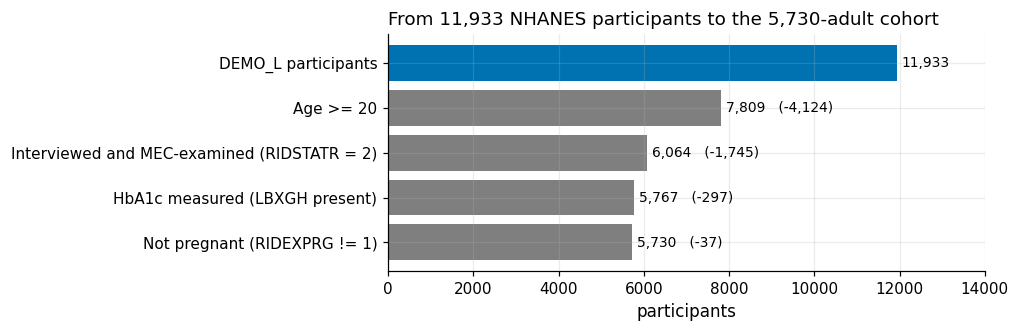

saved figures/S3_funnel.png


In [7]:
uniq = []
demo_ids = set(demo["SEQN"])
for f in C.NHANES_FILES:
    ids = io.read_xpt(f)["SEQN"]
    uniq.append({"file": f, "rows": len(ids), "seqn_unique": ids.is_unique, "subset_of_DEMO": set(ids) <= demo_ids})
uniq = pd.DataFrame(uniq)
display(uniq)
assert uniq["seqn_unique"].all() and uniq["subset_of_DEMO"].all()

fun = io.funnel()
display(fun)
assert tuple(fun["n"]) == io.FUNNEL_EXPECTED
preg3 = int(coh["preg_unknown"].sum())
print(f"cohort N = {len(coh):,}; RIDEXPRG = 3 (cannot ascertain) kept and flagged: {preg3}")
assert preg3 == 21

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(fun["step"][::-1], fun["n"][::-1], color=[OI["grey"]] * 4 + [OI["blue"]])
for y, (n, d) in enumerate(zip(fun["n"][::-1], fun["dropped"][::-1])):
    ax.text(n + 120, y, f"{n:,}" + (f"   (-{d:,})" if d else ""), va="center", fontsize=9)
ax.set_xlabel("participants"); ax.set_xlim(0, 14000)
ax.set_title("From 11,933 NHANES participants to the 5,730-adult cohort", loc="left")
f_funnel = plots.savefig(fig, "S3_funnel", caption="Sample funnel: DEMO_L participants -> age >= 20 -> interviewed and examined -> HbA1c measured -> not pregnant (N = 5,730). Numbers in brackets are the rows removed at each step.")
plt.show(); print("saved", f_funnel)

**So what.** `SEQN` is unique in all 16 files, and each file is a subset of `DEMO_L`, so the left join neither duplicates nor drops anyone. The funnel reproduces the specification exactly: 11,933 → 7,809 (age ≥ 20) → 6,064 (examined) → 5,767 (HbA1c present) → 5,730 (pregnant women removed). The largest selective step is the examination (1,745 adults lost). Together with the 25.7 % examination response rate it limits representativeness, which is why the quality matrix in item 9 rates credibility separately. The 297 examined adults without HbA1c are studied in item 7. The 21 women whose pregnancy status could not be ascertained are kept and flagged (`preg_unknown`), so a sensitivity analysis can drop them.

In [8]:
M3["funnel"] = dict(zip(fun["step"], fun["n"].astype(int)))
M3["uniqueness"] = {"files_seqn_unique": int(uniq["seqn_unique"].sum()), "files_subset_of_demo": int(uniq["subset_of_DEMO"].sum())}
M3["preg_unknown_kept"] = preg3

## 3 Per-variable sentinel map

**Why.** NHANES codes "Refused" and "Don't know" differently in each variable: 7/9, 77/99, 777/999 or 7777/9999. Continuous laboratory and examination measures have no such codes at all; their codebook lists only a range of values and "Missing". The sentinel map is therefore taken from each variable's codebook entry, never from a global list. Two kinds of check make it auditable:

- Every recoded code is traceable to the codebook: for each variable, the number of rows recoded in the raw file must equal the frequency the CDC codebook prints for that code.
- Codes that look like sentinels but are real categories are kept. Examples are `DIQ010 = 3` (borderline) and `HUQ030 = 3` (more than one place of care).

In [9]:
cb = io.codebook_table()
rows = []
for f in C.NHANES_FILES:
    part = io.load_file(f, spec=spec)[0]
    _, aud = io.apply_sentinels(part, spec, mode="per_variable")
    for _, a in aud.iterrows():
        codes = io._codes(a["codes"])
        cbv = cb[(cb["file"] == f) & (cb["var"] == a["var"])]
        cb_rows = cbv[cbv["code"].isin([str(c) for c in codes])]
        rows.append({"var": a["var"], "file": f, "codes": a["codes"],
                     "codebook_desc": " / ".join(cb_rows["desc"]),
                     "codebook_count": int(cb_rows["count"].sum()),
                     "recoded_file": int(a["n_recoded"])})
sent = pd.DataFrame(rows)
_, aud_coh = io.apply_sentinels(io.build_cohort(sentinels="none"), spec, mode="per_variable")
sent = sent.merge(aud_coh[["var", "n_recoded"]].rename(columns={"n_recoded": "recoded_cohort"}), on="var", how="left")
sent["traceable"] = sent["codebook_count"] == sent["recoded_file"]
display(sent)
sent.to_csv(OUT / "sentinel_audit.csv", index=False, lineterminator="\n")
assert sent["traceable"].all(), sent[~sent["traceable"]]
assert len(sent) == 25 and int(sent["recoded_file"].sum()) == 1047
assert sent["codebook_desc"].str.split(" / ").map(lambda d: all(x in ("Refused", "Don't know") for x in d)).all()

legit = pd.DataFrame([
    ["DIQ010 = 3", "Borderline", int((coh["DIQ010"] == 3).sum()), int((io.read_xpt("DIQ_L")["DIQ010"] == 3).sum())],
    ["HUQ030 = 3", "There is more than one place", int((coh["HUQ030"] == 3).sum()), int((io.read_xpt("HUQ_L")["HUQ030"] == 3).sum())],
    ["RIDRETH3 = 7", "Other race, including multi-racial", int((coh["RIDRETH3"] == 7).sum()), int((demo["RIDRETH3"] == 7).sum())],
], columns=["code", "meaning", "cohort", "file"])
display(legit)
assert legit.loc[0, "cohort"] == 213 and legit.loc[0, "file"] == 284
n_sent_coh = int(sent["recoded_cohort"].fillna(0).sum())
print(f"variables with codebook sentinels: {len(sent)}; cells recoded in the files: {int(sent['recoded_file'].sum()):,}; in the cohort: {n_sent_coh:,}")

,var,file,codes,codebook_desc,codebook_count,recoded_file,recoded_cohort,traceable
0,DMDEDUC2,DEMO_L,7;9,Refused / Don't know,11,11,2,True
1,DMDMARTZ,DEMO_L,77;99,Refused / Don't know,9,9,4,True
2,DIQ010,DIQ_L,7;9,Refused / Don't know,4,4,0,True
3,DID040,DIQ_L,777;999,Refused / Don't know,24,24,14,True
4,DIQ160,DIQ_L,7;9,Refused / Don't know,15,15,8,True
5,DIQ180,DIQ_L,7;9,Refused / Don't know,267,267,173,True
6,DIQ050,DIQ_L,7;9,Refused / Don't know,0,0,0,True
7,DID060,DIQ_L,777;999,Refused / Don't know,8,8,6,True
8,DIQ070,DIQ_L,7;9,Refused / Don't know,7,7,4,True
9,BPQ020,BPQ_L,7;9,Refused / Don't know,11,11,4,True


,code,meaning,cohort,file
0,DIQ010 = 3,Borderline,213,284
1,HUQ030 = 3,There is more than one place,34,57
2,RIDRETH3 = 7,"Other race, including multi-racial",363,948


variables with codebook sentinels: 25; cells recoded in the files: 1,047; in the cohort: 562


**So what.** For each of the 25 variables with codebook sentinels, the number of recoded rows equals the frequency the codebook prints, so each recode is traceable to its CDC source. The map recodes 1,047 cells across the files and 562 in the cohort. The largest single item is `DIQ180` (prior blood test, 173 "don't know"), a label-audit variable rather than a predictor.

The codes that look like sentinels but are categories stay untouched:

- 213 borderline answers (`DIQ010 = 3`; 284 in the file);
- 34 people with more than one usual place of care (`HUQ030 = 3`);
- the 363 "Other race / multiracial" adults (`RIDRETH3 = 7`).

**Decision (DR-S3-02):** recode refusal and don't-know codes per variable from the codebook (`apply_sentinels(mode="per_variable")`). There is no global list, and continuous measures are never recoded.

In [10]:
M3["sentinel_audit"] = {"n_variables": len(sent), "cells_recoded_files": int(sent["recoded_file"].sum()),
                        "cells_recoded_cohort": n_sent_coh, "all_traceable": bool(sent["traceable"].all()),
                        "legit_codes_cohort": dict(zip(legit["code"], legit["cohort"].astype(int)))}

## 4 Cost of a blanket recode

**Why.** A common shortcut is `df.replace([7, 9, 77, 99, 777, 999, 7777, 9999], np.nan)` across the whole table. It is also the "minimal" arm M0 of the experiments in Stage S6. The cost has to be measured rather than assumed. Every value the shortcut removes from a continuous measure is a valid measurement, because those variables have no refusal codes. Examples are a diastolic pressure of 77 mmHg, a weight of 99 kg and an HbA1c of 7.0 %. The damage is counted on the fixed cohort of 5,730 adults in three arms:

- **per-variable**: codebook codes only;
- **blanket**: the shortcut;
- **questionnaire-only**: the shortcut restricted to the six questionnaire items where it is harmless.

The effect on the labels is counted as well.

In [11]:
coh_none = io.build_cohort(sentinels="none")
DERIVED = ["bp_sys_mean", "bp_dia_mean", "whtr", "age_top", "pir_top", "pir_miss", "preg_unknown", "race", "sex"]
coh_blank = io.build_cohort(sentinels="blanket")
codes = list(io.BLANKET_CODES)
dmg = pd.DataFrame({"var": io.CONTINUOUS_CANDIDATES})
dmg["valid_cells_destroyed"] = [int(coh_none[v].isin(codes).sum()) for v in dmg["var"]]
dmg["lost_in_blanket_cohort"] = [int(coh_none[v].notna().sum() - coh_blank[v].notna().sum()) for v in dmg["var"]]
dmg["values_hit"] = [", ".join(f"{io._num(k)}:{n}" for k, n in coh_none.loc[coh_none[v].isin(codes), v].value_counts().sort_index().items()) for v in dmg["var"]]
assert (dmg["valid_cells_destroyed"] == dmg["lost_in_blanket_cohort"]).all()
assert (spec.set_index("var").loc[list(io.CONTINUOUS_CANDIDATES), "sentinel_codes"].groupby(level=0).first() == "").all()
dmg = dmg.sort_values("valid_cells_destroyed", ascending=False).reset_index(drop=True)
display(dmg)
dmg.to_csv(OUT / "blanket_damage.csv", index=False, lineterminator="\n")
n_destroyed = int(dmg["valid_cells_destroyed"].sum())

# same 20 variables in the full merged file (secondary scope)
full_none = io.load_merged(sentinels="none")
n_destroyed_full = int(sum(full_none[v].isin(codes).sum() for v in io.CONTINUOUS_CANDIDATES))

# labels
a1c_pos = coh_none["LBXGH"] >= C.HBA1C_DIABETES
a1c_pos_blank = coh_blank["LBXGH"] >= C.HBA1C_DIABETES
lost_pos = int((a1c_pos & ~a1c_pos_blank).sum())
lost_values = coh_none.loc[a1c_pos & ~a1c_pos_blank, "LBXGH"].value_counts().to_dict()
self_dm = coh["DIQ010"] == 1
l_comb = self_dm | a1c_pos
l_comb_blank = self_dm | a1c_pos_blank
flips = int((l_comb & ~l_comb_blank).sum())

# questionnaire-only arm: genuine codes in the six questionnaire items
q_arm = pd.Series({v: int(coh_none[v].isin(io.sentinel_map(spec)[v]).sum()) for v in io.QUESTIONNAIRE_ITEMS})
n_q = int(q_arm.sum())

# blanket on every numeric column: genuine codes vs valid values
_, aud_blank = io.apply_sentinels(coh_none.drop(columns=DERIVED), spec, mode="blanket")
smap = io.sentinel_map(spec)
aud_blank["genuine"] = [int(coh_none[v].isin(smap.get(v, [])).sum()) for v in aud_blank["var"]]
aud_blank["valid_destroyed"] = aud_blank["n_recoded"] - aud_blank["genuine"]
n_blank_all, n_blank_genuine = int(aud_blank["n_recoded"].sum()), int(aud_blank["genuine"].sum())
other_valid = aud_blank[(aud_blank["valid_destroyed"] > 0) & ~aud_blank["var"].isin(io.CONTINUOUS_CANDIDATES)].sort_values("valid_destroyed", ascending=False)

print(f"valid cells destroyed in the cohort (20 continuous candidates): {n_destroyed:,}; same 20 variables in the full file: {n_destroyed_full:,}")
print(f"HbA1c positives lost: {lost_pos}/{int(a1c_pos.sum())} ({lost_pos / a1c_pos.sum():.1%}); values {lost_values}")
print(f"L_comb positives flipped to negative: {flips}/{int(l_comb.sum())}")
print(f"questionnaire-only arm: {n_q} genuine codes {q_arm.to_dict()}")
print(f"blanket over all numeric columns of the cohort: {n_blank_all:,} cells recoded, of which genuine refusal/don't-know {n_blank_genuine:,}")
display(other_valid[["var", "n_recoded", "genuine", "valid_destroyed", "by_code"]].head(12))

assert n_destroyed == 1496 and n_destroyed_full == 2472
assert lost_pos == 29 and int(a1c_pos.sum()) == 721 and lost_values == {7.0: 28, 9.0: 1}
assert flips == 6 and int(l_comb.sum()) == 971
assert n_q == 57 and q_arm.to_dict() == {"HIQ011": 9, "HUQ030": 1, "BPQ020": 4, "BPQ080": 34, "SMQ020": 7, "DMDEDUC2": 2}

,var,valid_cells_destroyed,lost_in_blanket_cohort,values_hit
0,BPXODI1,237,237,"77:214, 99:23"
1,BPXODI2,224,224,"77:209, 99:15"
2,BPXODI3,200,200,"77:182, 99:18"
3,BPXOPLS1,157,157,"77:139, 99:18"
4,BPXOPLS3,155,155,"77:138, 99:17"
5,BPXOPLS2,148,148,"77:127, 99:21"
6,RIDAGEYR,65,65,77:65
7,BPXOSY1,57,57,"77:2, 99:55"
8,BPXOSY3,56,56,"77:1, 99:55"
9,BPXOSY2,54,54,"77:1, 99:53"


valid cells destroyed in the cohort (20 continuous candidates): 1,496; same 20 variables in the full file: 2,472
HbA1c positives lost: 29/721 (4.0%); values {7.0: 28, 9.0: 1}
L_comb positives flipped to negative: 6/971
questionnaire-only arm: 57 genuine codes {'HIQ011': 9, 'HUQ030': 1, 'BPQ020': 4, 'BPQ080': 34, 'SMQ020': 7, 'DMDEDUC2': 2}
blanket over all numeric columns of the cohort: 3,132 cells recoded, of which genuine refusal/don't-know 562


,var,n_recoded,genuine,valid_destroyed,by_code
49,PAD790Q,405,25,380,7:380;7777:4;9999:21
3,RIDRETH3,363,0,363,7:363
9,LBXGLU,125,0,125,77:6;99:119
28,LBDLDL,63,0,63,77:25;99:38
51,PAD810Q,80,22,58,7:57;9:1;9999:22
27,LBXTLG,57,0,57,77:29;99:28
34,DID060,26,6,20,7:18;9:2;999:6
30,DID040,17,14,3,7:1;9:1;77:1;999:14
50,PAD800,16,13,3,7:3;9999:13
52,PAD820,10,9,1,7:1;7777:1;9999:8


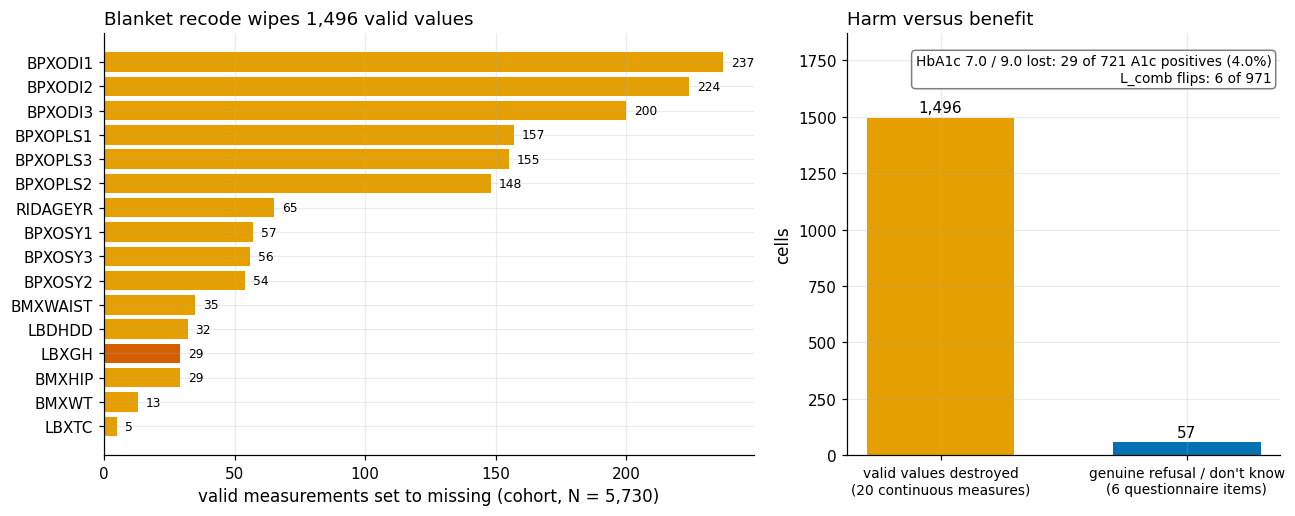

saved figures/S3_blanket_recode_damage.png


In [12]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
d = dmg[dmg["valid_cells_destroyed"] > 0].iloc[::-1]
col = [OI["vermillion"] if v == "LBXGH" else OI["orange"] for v in d["var"]]
a1.barh(d["var"], d["valid_cells_destroyed"], color=col)
for y, n in enumerate(d["valid_cells_destroyed"]):
    a1.text(n + 3, y, str(n), va="center", fontsize=8)
a1.set_xlabel("valid measurements set to missing (cohort, N = 5,730)")
a1.set_title(f"Blanket recode wipes {n_destroyed:,} valid values", loc="left")
bars = [("valid values destroyed\n(20 continuous measures)", n_destroyed, OI["orange"]),
        ("genuine refusal / don't know\n(6 questionnaire items)", n_q, OI["blue"])]
a2.bar([b[0] for b in bars], [b[1] for b in bars], color=[b[2] for b in bars], width=0.6)
for x, b in enumerate(bars):
    a2.text(x, b[1] + 25, f"{b[1]:,}", ha="center", fontsize=10)
a2.set_ylabel("cells"); a2.set_ylim(0, n_destroyed * 1.25); a2.tick_params(axis="x", labelsize=9)
a2.set_title("Harm versus benefit", loc="left")
a2.text(0.98, 0.95, f"HbA1c 7.0 / 9.0 lost: {lost_pos} of {int(a1c_pos.sum())} A1c positives ({lost_pos / a1c_pos.sum():.1%})\n"
        f"L_comb flips: {flips} of {int(l_comb.sum())}", transform=a2.transAxes, ha="right", va="top", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec=OI["grey"]))
fig.tight_layout()
f_blank = plots.savefig(fig, "S3_blanket_recode_damage",
                        caption=f"Left: valid measurements removed by a blanket recode of 7/9/77/99/777/999/7777/9999 in the cohort, by variable "
                                f"({n_destroyed:,} in total; HbA1c in red). Right: the shortcut destroys {n_destroyed:,} valid values to clean {n_q} genuine "
                                f"refusal/don't-know answers in the questionnaire items; it removes {lost_pos}/{int(a1c_pos.sum())} HbA1c-defined positives, "
                                f"of which {flips} of {int(l_comb.sum())} L_comb positives flip.")
plt.show(); print("saved", f_blank)

**So what.** On the same 5,730 adults, the blanket recode destroys **1,496 valid measurements** across the 20 continuous candidates. Most fall on diastolic pressure and pulse, where 77 and 99 are ordinary readings. Over the whole release the same 20 variables lose 2,472 values, a secondary count. The harm reaches the label:

- All 29 HbA1c values it removes are 7.0 % (28) or 9.0 % (1), so every one is a true diabetic value. That is **29 of the 721 HbA1c-defined positives (4.0 %)** lost.
- Under the frozen `L_comb` only **6 of 971** positives flip, because the other 23 also report a diagnosis. Self-report hides the error, which makes it easy to miss.

Applied to every numeric column, the shortcut also wipes categorical codes that are real categories. Examples are `RIDRETH3 = 7` (the 363 multiracial adults disappear as a group), 380 moderate-activity frequencies of 7 sessions (`PAD790Q`) and age 77.

The benefit side is small. Restricting the shortcut to the six questionnaire items cleans just **57** genuine codes, so the shortcut's harm exceeds its gain by a factor of about 26. **Decision (DR-S3-02, evidence):** the per-variable map is the systematic arm. The blanket recode is kept only as the deliberately naive M0 arm in Stage S6, where its cost becomes measurable in model terms.

In [13]:
M3["blanket_recode"] = {
    "valid_cells_destroyed_cohort": n_destroyed, "valid_cells_destroyed_full_file_same_20_vars": n_destroyed_full,
    "candidates": list(io.CONTINUOUS_CANDIDATES),
    "per_variable": dict(zip(dmg["var"], dmg["valid_cells_destroyed"].astype(int))),
    "a1c_positives_lost": lost_pos, "a1c_positives": int(a1c_pos.sum()), "a1c_lost_share": lost_pos / int(a1c_pos.sum()),
    "l_comb_flips": flips, "l_comb_positives": int(l_comb.sum()),
    "questionnaire_only_cells": n_q, "questionnaire_only_per_item": q_arm.to_dict(),
    "all_numeric_recoded": n_blank_all, "all_numeric_genuine": n_blank_genuine,
    "ridreth3_7_destroyed": int(aud_blank.set_index("var").loc["RIDRETH3", "valid_destroyed"]),
}